# Fix `ddm_st` and `ddm_normal_st` fits that won't converge

`ddm_st` and `ddm_normal_st` add trial-to-trial variability in non-decision time to the
DDM. Both are fitted through a likelihood approximation network (LAN), a neural network
trained to return the model's log-density. Their failures rarely raise an error: the
chains stick, or the fit converges cleanly and recovers the wrong values.

This notebook reproduces each failure on simulated data and shows the fix.

| # | symptom | cause |
|---|---|---|
| 1 | `t` biased, no error | an HSSM older than 0.5.1 floors responses faster than `t` |
| 2 | HSSM refuses the data | simulated response times at or below zero |
| 3 | clean diagnostics, wrong group means | the default prior on the group means |
| 4 | small, fixed bias that more data does not remove | a lapse term the data do not have |
| 5 | `st` values that disagree between the two models | `st` means different things in each |

Set `FULL_RUN=1` to reproduce the saved outputs (12 subjects, 300 trials each, about 25
minutes on four CPU cores). The default is a quick run for continuous integration, whose
numbers are too noisy to read.

In [1]:
import os

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ssms
from ssms.basic_simulators.simulator import simulator

import hssm
from hssm.modelconfig import get_default_model_config

FULL_RUN = os.environ.get("FULL_RUN", "0") == "1"
if FULL_RUN:
    N_SUBJECTS, N_TRIALS = 12, 300
    SAMPLE_KWARGS = dict(chains=4, draws=1000, tune=1000)
else:
    N_SUBJECTS, N_TRIALS = 6, 150
    SAMPLE_KWARGS = dict(chains=2, draws=200, tune=200)
SAMPLE_KWARGS.update(
    sampler="numpyro", cores=1, random_seed=0, idata_kwargs={"log_likelihood": False}
)

# Set DDM_ST_ONNX / DDM_NORMAL_ST_ONNX to use a local network file instead of the
# one HSSM downloads from franklab/HSSM.
LOCAL_NET = {
    m: os.environ.get(f"{m.upper()}_ONNX") for m in ("ddm_st", "ddm_normal_st")
}


def network(model):
    """Return the `loglik` override for `model` when a local file is set."""
    return {"loglik": LOCAL_NET[model]} if LOCAL_NET[model] else {}


print(
    f"hssm {hssm.__version__}, ssm-simulators {ssms.__version__}, FULL_RUN={FULL_RUN}"
)

hssm 0.5.1, ssm-simulators 0.16.0, FULL_RUN=True


## The model

On each trial the non-decision time `tau` is drawn from a kernel centred on `t`, and the
response time is `tau` plus the first-passage time of a Wiener process:

```text
ddm_st:         tau ~ Uniform(t - st, t + st)      st is a half-width
ddm_normal_st:  tau ~ Normal(t, st)                st is a standard deviation

(rt, response) = tau + first passage of a Wiener process with drift v,
                 boundary separation a, starting point z * a
```

HSSM evaluates, for each trial,

```text
p(rt, response) = (1 - p_outlier) * f_LAN(rt, response | v, a, z, t, st)
                  + p_outlier * Uniform(rt; 0, 20)
```

where `f_LAN` is the network's density, floored for responses below the model's support
edge (section 1).

We simulate `ddm_st` data for several subjects. `v`, `a`, `z` and `t` vary by subject;
`st` is shared. There are no lapses in these data.

In [2]:
rng = np.random.default_rng(2026)
ST_TRUE = 0.13
subjects = pd.Index([f"s{i}" for i in range(N_SUBJECTS)], name="subject")
truth = pd.DataFrame(
    {
        "v": np.clip(rng.normal(1.0, 0.30, N_SUBJECTS), -2.5, 2.5),
        "a": np.clip(rng.normal(1.2, 0.20, N_SUBJECTS), 0.5, 2.0),
        "z": np.clip(rng.normal(0.5, 0.05, N_SUBJECTS), 0.35, 0.65),
        "t": np.clip(rng.normal(0.4, 0.05, N_SUBJECTS), 0.30, 0.55),
    },
    index=subjects,
)

frames = []
for i, (subject, row) in enumerate(truth.iterrows()):
    sim = simulator(
        model="ddm_st",
        theta={**row.to_dict(), "st": ST_TRUE},
        n_samples=N_TRIALS,
        random_state=i,
    )
    frames.append(
        pd.DataFrame(
            {
                "rt": sim["rts"].ravel(),
                "response": sim["choices"].ravel(),
                "subject": subject,
            }
        )
    )
data = pd.concat(frames, ignore_index=True)
data = data[data["rt"] > 0].reset_index(drop=True)  # section 2
print(f"{len(data)} trials from {N_SUBJECTS} subjects")
truth.round(3)

3600 trials from 12 subjects


,v,a,z,t
subject,,,,
s0,0.762,1.187,0.532,0.374
s1,1.072,1.183,0.591,0.377
s2,0.431,1.232,0.464,0.425
s3,1.419,1.077,0.567,0.444
s4,1.191,1.119,0.438,0.410
s5,0.912,1.310,0.509,0.369
s6,0.906,1.174,0.442,0.359
s7,1.091,0.925,0.568,0.472
s8,0.920,1.105,0.542,0.430


## 1. Responses faster than `t`

**Symptom:** `t` comes out biased, with no error and no warning.

Non-decision time varies around `t`, so a response can be faster than `t` whenever the
decision itself takes less time than the kernel shifts it. HSSM floors the likelihood of any
response below the model's support edge. For a plain DDM that edge is `t`; these models
declare a lower one. How many responses fall in between depends on the design: none in the
data above, where every decision takes longer than `st`, and many when boundaries are close
and `st` is wide.

In [3]:
below_t = (data["rt"] < data["subject"].map(truth["t"])).mean()
print(f"simulated data above: {below_t:.1%} of responses faster than t")

close = {"v": 1.0, "a": 0.5, "z": 0.5, "t": 0.4, "st": 0.3}
for model in ("ddm_st", "ddm_normal_st"):
    rts = simulator(model=model, theta=close, n_samples=100_000, random_state=0)["rts"]
    share = np.mean(rts < close["t"])
    print(f"{model:14s} at a=0.5, st=0.3: {share:.1%} of responses faster than t")

print()
for model in ("ddm_st", "ddm_normal_st"):
    likelihood = get_default_model_config(model)["likelihoods"]["approx_differentiable"]
    print(
        f"{model:14s} support starts at t - "
        f"{likelihood['ndt_edge_shift']['scale']} * st"
    )

simulated data above: 0.0% of responses faster than t


ddm_st         at a=0.5, st=0.3: 18.0% of responses faster than t


ddm_normal_st  at a=0.5, st=0.3: 24.6% of responses faster than t

ddm_st         support starts at t - 1.0 * st
ddm_normal_st  support starts at t - 3.0 * st


HSSM 0.5.1 and later read this declaration (#1292). Earlier versions floor every response
faster than `t`, discarding the density of the trials counted above. The fit still runs, `t`
moves to compensate, and the result looks like awkward sampler geometry.

**Fix:** use HSSM 0.5.1 or later.

## 2. Response times at or below zero

**Symptom:** HSSM refuses to build the model from simulated data.

Where `st` is large and `t` small, the kernel reaches below zero, and so do some simulated
response times. At the corner of the training box:

In [4]:
corner = {"v": 0.0, "a": 0.3, "z": 0.5, "t": 0.25, "st": 0.35}
for model in ("ddm_st", "ddm_normal_st"):
    rts = simulator(model=model, theta=corner, n_samples=100_000, random_state=0)["rts"]
    print(f"{model:14s} {np.mean(rts <= 0):5.1%} of responses at or below zero")

bad = pd.DataFrame({"rt": [-0.05, 0.40, 0.55], "response": [1, -1, 1]})
try:
    hssm.HSSM(data=bad, model="ddm_st", **network("ddm_st"))
except Exception as err:  # noqa: BLE001
    print(f"\n{type(err).__name__}: {err}")

ddm_st          4.1% of responses at or below zero


ddm_normal_st  16.3% of responses at or below zero

ValueError: You have negative response times in your dataset, which is not allowed.


**Fix:** drop non-positive response times from simulated data before fitting, as the
simulation cell above does. Real data never contain them.

The same region of the box is also where the networks are least reliable, so keep every
parameter inside the bounds the models declare. They are the networks' training box:

In [5]:
BOUNDS = get_default_model_config("ddm_st")["likelihoods"]["approx_differentiable"][
    "bounds"
]
pd.DataFrame(BOUNDS, index=["lower", "upper"])

,v,a,z,t,st
lower,-3.0,0.3,0.3,0.25,0.001
upper,3.0,2.5,0.7,2.25,0.350


## 3. Clean diagnostics, wrong group means

**Symptom:** the hierarchical fit converges (r-hat near 1, no divergences) and the
per-subject estimates look right, but the group-level means and spreads are wrong.

Each parameter is modelled on the link scale. With `link_settings="log_logit"` a parameter
bounded on both sides uses the generalized logit, so for parameter `p` with bounds `(lo, hi)`:

```text
p[subject]  = lo + (hi - lo) / (1 + exp(-eta[subject]))
eta[subject] ~ Normal(mu_p, sigma_p)
mu_p         ~ Normal(0, 0.25)        HSSM's default for a group intercept
sigma_p      ~ Weibull(1.5, 0.3)
```

The HSSM formula is `p ~ 0 + (1|subject)` for each of `v`, `a`, `z`, `t`. `mu_p = 0` maps to
the midpoint of the bounds, so a narrow prior around 0 pulls every group mean toward that
midpoint.

In [6]:
PARAMS = ["v", "a", "z", "t"]


def hierarchical(prior=None, p_outlier=None):
    """ddm_st with a subject-level intercept on v, a, z and t; st shared."""
    include = [
        {
            "name": p,
            "formula": f"{p} ~ 0 + (1|subject)",
            **({"prior": {"1|subject": prior}} if prior is not None else {}),
        }
        for p in PARAMS
    ]
    return hssm.HSSM(
        data=data,
        model="ddm_st",
        include=include,
        p_outlier=p_outlier,
        link_settings="log_logit",
        prior_settings="safe",
        noncentered=False,
        **network("ddm_st"),
    )


idata_default = hierarchical().sample(**SAMPLE_KWARGS)

Model initialized successfully.


Using default initvals. 



In [7]:
def diagnostics(idata, label):
    """Worst-case convergence numbers over every parameter in the posterior."""
    summary = az.summary(idata)
    return pd.Series(
        {
            "worst r_hat": summary["r_hat"].max(),
            "min ESS bulk": summary["ess_bulk"].min(),
            "divergent %": 100
            * float(np.asarray(idata.sample_stats["diverging"]).mean()),
        },
        name=label,
    )


def inv_link(eta, p):
    """Map link-scale values of parameter `p` back into its bounds."""
    lo, hi = BOUNDS[p]
    return lo + (hi - lo) / (1 + np.exp(-eta))


def population(idata, label, n_draws=400, n_subjects=4000, seed=0):
    """Estimate the population mean and SD on the natural scale.

    The group distribution lives on the link scale, so it is pushed through the
    inverse link by simulation; inv_link(mu_p) alone is the median, not the mean.
    """
    rng = np.random.default_rng(seed)
    post = idata.posterior
    rows = {}
    for p in PARAMS:
        mu = np.asarray(post[f"{p}_1|subject_mu"]).ravel()
        sigma = np.asarray(post[f"{p}_1|subject_sigma"]).ravel()
        pick = rng.choice(mu.size, size=n_draws, replace=False)
        x = inv_link(
            rng.normal(mu[pick, None], sigma[pick, None], (n_draws, n_subjects)), p
        )
        rows[p] = {"mean": x.mean(), "SD": x.std(axis=1).mean()}
    rows["st"] = {"mean": float(np.asarray(post["st"]).mean()), "SD": np.nan}
    return pd.DataFrame(rows).T.add_prefix(f"{label} ")


TRUE_POP = pd.DataFrame(
    {"true mean": [*truth.mean(), ST_TRUE], "true SD": [*truth.std(ddof=0), np.nan]},
    index=[*PARAMS, "st"],
)
print(diagnostics(idata_default, "default prior").round(3).to_string())
pd.concat([TRUE_POP, population(idata_default, "default")], axis=1).round(3)

worst r_hat        1.004
min ESS bulk    1555.148
divergent %        0.000


,true mean,true SD,default mean,default SD
v,1.001,0.242,0.930,0.328
a,1.164,0.102,1.186,0.121
z,0.517,0.051,0.511,0.046
t,0.414,0.046,0.929,0.431
st,0.130,NaN,0.131,NaN


The diagnostics give no hint of a problem. The group mean of `t` has moved from 0.41 to 0.93,
more than halfway to the midpoint of its bounds (1.25), and its spread is inflated about nine
times, which keeps every subject reachable from the misplaced mean. `v`, `a` and `z` survive
on this dataset; on others `v` moves too.

**Fix:** a wider prior on the group means. Everything else stays the same.

In [8]:
group_prior = bmb.Prior(
    "Normal",
    mu=bmb.Prior("Normal", mu=0.0, sigma=2.0),
    sigma=bmb.Prior("Weibull", alpha=1.5, beta=0.3),
)
idata_wide = hierarchical(group_prior).sample(**SAMPLE_KWARGS)

print(
    pd.concat(
        [
            diagnostics(idata_default, "default prior"),
            diagnostics(idata_wide, "Normal(0, 2)"),
        ],
        axis=1,
    )
    .round(3)
    .to_string()
)
pd.concat(
    [
        TRUE_POP,
        population(idata_default, "default"),
        population(idata_wide, "Normal(0, 2)"),
    ],
    axis=1,
).round(3)

Model initialized successfully.


Using default initvals. 



              default prior  Normal(0, 2)
worst r_hat           1.004         1.006
min ESS bulk       1555.148       689.322
divergent %           0.000         0.900


,true mean,true SD,default mean,default SD,"Normal(0, 2) mean","Normal(0, 2) SD"
v,1.001,0.242,0.930,0.328,1.003,0.322
a,1.164,0.102,1.186,0.121,1.175,0.110
z,0.517,0.051,0.511,0.046,0.513,0.046
t,0.414,0.046,0.929,0.431,0.414,0.047
st,0.130,NaN,0.131,NaN,0.127,NaN


With the wider prior the group means and spreads match the truth. This fit had 0.9% divergent
transitions and a lower effective sample size than the default; both are within what most
analyses accept, and raising `target_accept` is the usual remedy if they are not.

The trace of each group mean shows the same thing. The dashed line is the median of the
true subject values, which is what `inv_link(mu_p)` estimates. Agreeing, well-mixed chains
far from that line are what a converged but wrong fit looks like.

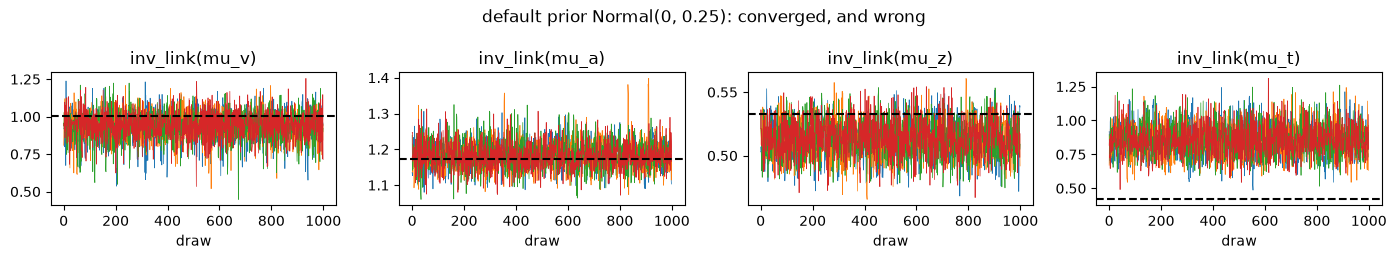

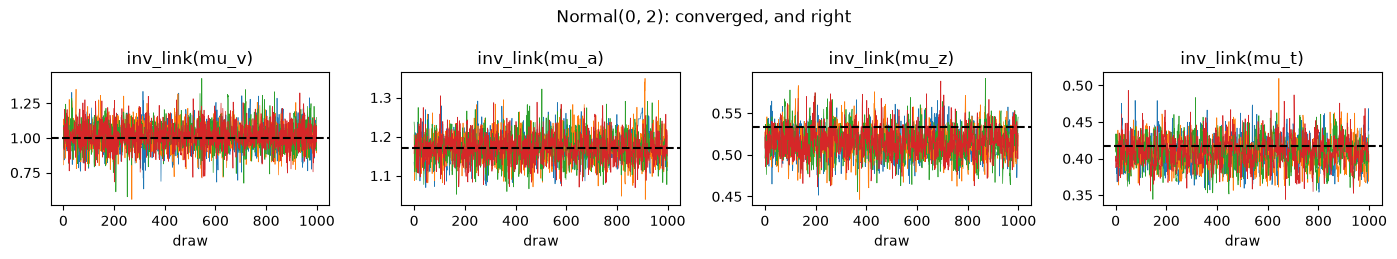

In [9]:
def plot_group_medians(idata, title):
    """Plot each chain of inv_link(mu_p) against the median of the true values."""
    fig, axes = plt.subplots(1, len(PARAMS), figsize=(14, 2.6))
    post = idata.posterior
    for ax, p in zip(axes, PARAMS):
        for chain in np.asarray(post[f"{p}_1|subject_mu"]):
            ax.plot(inv_link(chain, p), lw=0.5)
        ax.axhline(truth[p].median(), color="k", ls="--")
        ax.set_title(f"inv_link(mu_{p})")
        ax.set_xlabel("draw")
    fig.suptitle(title)
    fig.tight_layout()


plot_group_medians(idata_default, "default prior Normal(0, 0.25): converged, and wrong")
plot_group_medians(idata_wide, "Normal(0, 2): converged, and right")

## 4. A lapse term the data do not have

**Symptom:** a small bias that does not shrink as the dataset grows.

`p_outlier` mixes a uniform lapse distribution into every trial. HSSM's default is 0.05; the
fits above used `p_outlier=None` because these simulated data contain no lapses. Fitting the
same data with the default lapse:

In [10]:
idata_lapse = hierarchical(group_prior, p_outlier=0.05).sample(**SAMPLE_KWARGS)
pd.concat(
    [
        TRUE_POP,
        population(idata_wide, "p_outlier=None"),
        population(idata_lapse, "p_outlier=0.05"),
    ],
    axis=1,
).round(3)

Model initialized successfully.


Using default initvals. 



,true mean,true SD,p_outlier=None mean,p_outlier=None SD,p_outlier=0.05 mean,p_outlier=0.05 SD
v,1.001,0.242,1.003,0.322,1.068,0.326
a,1.164,0.102,1.175,0.110,1.169,0.106
z,0.517,0.051,0.513,0.046,0.503,0.044
t,0.414,0.046,0.414,0.047,0.414,0.048
st,0.130,NaN,0.127,NaN,0.126,NaN


On one dataset the difference is small and could go either way. The systematic effect
needs many datasets: on the plain DDM with its exact likelihood over 12 datasets, 94%
intervals covered the truth 96% of the time without the lapse and 88% with 0.05, at 500
trials, and the gap grows with more trials (LAN_pipeline_minimal's
[recovery guide](https://github.com/lnccbrown/LAN_pipeline_minimal/blob/main/docs/how-to/run-recovery-sweep.md)).

**Fix:** match the lapse to the data.

- **Simulated data without lapses:** `p_outlier=None`.
- **Real data:** keep a lapse term. Participants do lapse, and without it a few very fast or
  very slow responses can drag the DDM parameters.

The lapse does not unstick stuck chains. If the chains are stuck, look at sections 1 to 3.

## 5. `st` in `ddm_normal_st`

Everything above applies to `ddm_normal_st` too, with the same settings. Three things
differ. `st` is a standard deviation there and a half-width in `ddm_st`, so equal values are
not equal amounts of variability. The non-decision-time kernels of the two models, drawn
at the same `st`:

In [11]:
st = 0.2
for model in ("ddm_st", "ddm_normal_st"):
    kernel = ssms.config.model_config[model]["simulator_param_mappings"]["t_dist"](st)
    draws = kernel(size=200_000, random_state=0)
    print(
        f"{model:14s} st={st}: SD of the kernel {draws.std():.3f}, "
        f"lowest draw {draws.min():+.3f}"
    )
print(
    f"\nst={st} in ddm_st has the spread of st={st / np.sqrt(3):.3f} in ddm_normal_st"
)

ddm_st         st=0.2: SD of the kernel 0.116, lowest draw -0.200
ddm_normal_st  st=0.2: SD of the kernel 0.200, lowest draw -0.970

st=0.2 in ddm_st has the spread of st=0.115 in ddm_normal_st


The other two differences were shown above: the support starts at `t - 3 * st` rather
than `t - st` (section 1), and the box corner yields more non-positive response times
(section 2).

Each network's model card on the Hugging Face Hub lists where it is weaker than the exact
model. One entry matters here: `ddm_normal_st` reads `st` about 15% low when the true `st` is
between 0.05 and 0.11, and the offset does not shrink with more trials.

## Checklist

1. HSSM 0.5.1 or later.
2. Simulated data: drop `rt <= 0`; keep parameters inside the declared bounds.
3. Hierarchical fits: an explicit `Normal(0, 2)` prior on the group means, and check
   group-level recovery, not only the diagnostics.
4. `p_outlier=None` for lapse-free simulated data; a lapse term for real data.
5. Do not compare `st` across the two models without converting.